In [1]:
#import librries for project path management 

from pathlib import Path
import sys

#lets define the project root directory 
PROJECT_ROOT = Path.cwd().parent

#add the project root to module search path 
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))
#import the dataset path from project configuration 
from src.confingg import BREAST_DATASET

#import libraries for data analysis
import pandas as pd
import numpy as np
#import libraries for visualisation
import seaborn as sns
import matplotlib.pyplot as plt
#farhan shayan

در سلول بالا تمام کتابخانه های که لازم داشتیم و تمام  مسیر های که درون کانفینگ  فولدر سورس قرار دادیم را فرا خواندیم
و انها را به نام های مختصر مشخص کردیم فرهان شایان

In [2]:
%pip install seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: C:\Program Files\Python313\python.exe -m pip install --upgrade pip


در سلول بالا اقدام به نصب کتاب خانه سی بورن کردم فرهان شایان

در سلول پایین دیتا ست موجود در فولدر راا را صدا زده فرهان شایان

In [3]:
# load the raw dataset into a pandas dataframe 

df=pd.read_csv(BREAST_DATASET)
#farhan shayan

In [4]:
#display the  first five rows of the dataset 
df.head()
#farhan shayan


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


خب در این جدول که با دی اف هد پنج ردیف اول در اختیار ما قرار گرفته است  ما فیچر یا ویژگی هایی مانند 
میانگین فاصله مرکز تا لبه هسته   و محیط هسته و  تغییرات سطح خاکستری  بافت و یا تقارن هسته 
و همچنین پیچیدگی مرز هسته  و چیز های دیگری برسی می شود 
تغییرات سطح خاکستری بافت
تقارن هسته 
میانگین فاصله مرکز تا لبه هسته 
محیط هسته 
مساحت هسته
فشردگی شامل محیط و مساحت 
تعداد نقاط فرورفته  لبه 
پیچیدگی مرز هسته 
شدت قسمت های فرو رفته لبه
نکته بعد اینکه در اینجا 
بی به معنی خوش خیم بودن و 
ام به معنی بد خیم بودن است 

In [5]:
#dis play the number of rows and columns in the dataset (rows,columns)

df.shape
#farhan shayan

(569, 33)

خب در اینجا یعنی سلول بالا سی و سه   ستون داریم که ویزگی  ها را بیان می کند  و پانصد و شصت و نه ردیف داریم که  شامل بیماران میشود

In [6]:
#display dataset information including data types and non-null values

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

یک کارت شناسنایی از دیتا ست  به ما میده که شامل یک سری اطلاعات  هست  و ما باید یک سری عملیات ها را انجام دهیم  info خب 


یک ستون ناشناخته داریم که خالی است  و باید حذف شود  
نوع دیتا یا همون دیتا تایپ ها از نوع فلوت یا اعشاری است  
اما ای دی ما عدد صحیح است و باعث ناهماهنگی در مدل میشود  پس ان را در ادامه حذف خواهیم کرد 
نوع تارگت ها از نوع رشته  یا همون استرینگ هست که باید به  صفر و یک تبدیل شود 

In [7]:
#for making sure about non_null 
df.isnull().sum()
#farhan shayan

id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_worst      0
Unnamed:

خب برای مطمین شدن این کارو انجام دادیم  فقط یک نول خالی بود شماره سی و دو 
سوالی که ممکنه پیش بیاد اینه که  ما در سلول بالا مشاهده کردیم که نوع دیتا ما اعشاری یا فلوت هست  چرا اینجا دیتا تایپ 
صحیح یا اینتجر هست 
نوع دیتا تایپ به این دلیل اعداد صحیح است که نوع دیتا نهایی یعنی تعداد ستون و ردیف را در نظر میگیرد که عدد صحیح  است  نه نوع دیتا داخل دیتاست   همینطوری گفتم چون سوال برای خودمم پیش امده بود 

خب حالا وقتشه بریم سراغ ستون های تکراری 

In [8]:
#count the duplicated rows in data set 
df.duplicated().sum()
#farhan shayan

np.int64(0)

خب چک کردیم ببینیم  ستون تکراری داریم  یا نه  که نداریم 

مرحله بعد دیسکرایب کردن هست 

In [9]:
#generate descriptive statistics for numerical features
df.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


در سلول بالا میبینیم که از دسکرایب استفاده کردیم  که در اینجا یک خلاصه اماری از ستون های عددی به ما ارایه میکنه که از همه ستون ها به جز تارگت به ما گزارش می دهد 
در ردیف اولی مشاهده می کنیم تعداد ستون های پر را نشان میدهد  
و ردیف دومی به ما میانگین را نشان میدهد 
ردیف سومی در واقع اس تی دی را نشان میدهد  یعنی انحراف معیار  در واقع به این معنی که داد ها به چه اندازه در اطراف میانگین پخش شده اند و عدد بزگتر 
نشان دهنده ی  پراکندگی داده بیشتر است
مکس و مین نشان دهنده بیشترین و کمترین هستند در واقع 





در سلول پایین استاد از کلمه  ابجکت استفاده کردن اما من به دلیل اپدیت کردن پانداس از اس تس ار یا مختصر استرینگ استفاده کردم 

In [10]:
#generate descriptive statistic for categorical   features
df.describe(include="str")
#farhan shayan

,diagnosis
count,569
unique,2
top,B
freq,357


در سلول بالا خلاصه امار متنی رو داریم در این دیتا ست فقط یک  دیتا متنی داریم و نمیتونیم برای اونا از
معیار هایی مانند انحراف معیار و یا حتی میانگین استفاده کنیم پس در نتیجه پانداس معیار های دیگه در در نظر دارد
به عنوان مثال ردیف اول بیان میکند که همه ردیف ها مقدار دارند و هیچ ردیفی خالی نیست
در ردیف دوم یونیک به ما مقدار های مختلف تارگت رو نشون میده  ما فقط دو نوع خوش خیم و بد خیم داریم
ردیف سوم بیانگر این است که نوع بی یعنی خوش خیم  بیشتر تکرار شده است 
ردیف اخر میزان تکرار خوش خیم ها را بیان می کند  ما سیصد و پنجاه و هفت بیمار خوش خیم داشته ایم

حالا در سلول پایین می خوایم ستون هایی را برسی کنیم که مقادیر بولیین دارند 

طبق اموزش استاد در اینجا باید داده های بولین برسی میشد اما داده بولی نداریم

حالا سراغ برسی تارگت میریم

In [11]:
#count the number of samples in  each target class
df["diagnosis"].value_counts().sort_index()
#farhan shayan

diagnosis
B    357
M    212
Name: count, dtype: int64

خب حالا تعداد خوش خیم ها و بد خیم ها رو در اختیار داریم  
در سلول بعدی می خوایم یک متغییر بسازیم و این داده های تارگت رو درون اون بریزیم

In [12]:
target_counts=df["diagnosis"].value_counts().sort_index()
target_counts
#farhan shayan

diagnosis
B    357
M    212
Name: count, dtype: int64

در سلول بعدی قراره با کتابخانه مت پلات لیب  کار کنیم و بار رو رسم کنیم جوری که توازن رو بسنجیم

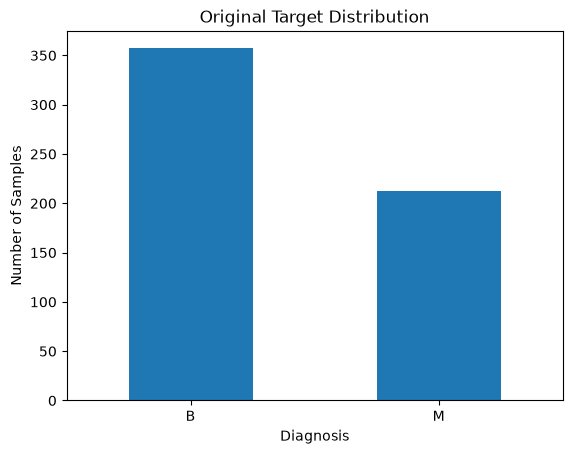

In [13]:
df["diagnosis"].value_counts(normalize=True) 
target_counts.plot(kind="bar")

plt.title("Original Target Distribution")

plt.xlabel("Diagnosis")

plt.ylabel("Number of Samples")

plt.xticks(rotation=0)

plt.show()
#farhan shayan

خب در سلول بالا میتوانیم ببینیم که امار و توازن داده ها یکسان نیست اما اختلاف توازن ها زیاد هم نیست و به نوعی منطقی است  داده ام که مربوط به سرطان نوع بدخیم است کمتر و داده ها نشان میدهم  ازمایش های مثبت بیشتر درباره نوع خوش خیم صدق می کند


In [14]:
#count the number of each target class 
df["diagnosis"].value_counts(normalize=True)
#farhan shayan


diagnosis
B    0.627417
M    0.372583
Name: proportion, dtype: float64

خب حالا امار و داده ها رو بدون بار و به صورت عددی مشاهده میکنیم که بسیار منطقی است

این مرحله برای برسی داده های عددی هست 

نامریکال فیچر یا شناخت ویژگی های عددی

در اینجا به جز ای دی و ستون سی و دو که خالی است به کمک ایف و فور ویژگی های عددی را درون یک لیست قرار داده  در این قسمت روش متفاوتی از استاد به کار گرفته 
شده زیرا دارای فیچر های عددی بیشتری بوده است

In [15]:

numerical_features = [
    col for col in df.select_dtypes(include="number").columns
    if col not in ["id", "Unnamed: 32"]
]

numerical_features

['radius_mean',
 'texture_mean',
 'perimeter_mean',
 'area_mean',
 'smoothness_mean',
 'compactness_mean',
 'concavity_mean',
 'concave points_mean',
 'symmetry_mean',
 'fractal_dimension_mean',
 'radius_se',
 'texture_se',
 'perimeter_se',
 'area_se',
 'smoothness_se',
 'compactness_se',
 'concavity_se',
 'concave points_se',
 'symmetry_se',
 'fractal_dimension_se',
 'radius_worst',
 'texture_worst',
 'perimeter_worst',
 'area_worst',
 'smoothness_worst',
 'compactness_worst',
 'concavity_worst',
 'concave points_worst',
 'symmetry_worst',
 'fractal_dimension_worst']

در سلول بالا تمامی ویژگی های عددی را برسی می کنیم برای این کار ابتدا همه انها را درون یک لیست قرار میدهیم از انجایی که استاد تعداد محدودی فیچر عددی در نظر گرفتند در این دیتا ست امکان همچین کاری نیست و همه فیچر ها دارای اهمیت هستند 

حالا سراغ رسم هیستوگرام میریم که نیازه یکم سایز هیستوگرام رو تغییر بدیم 

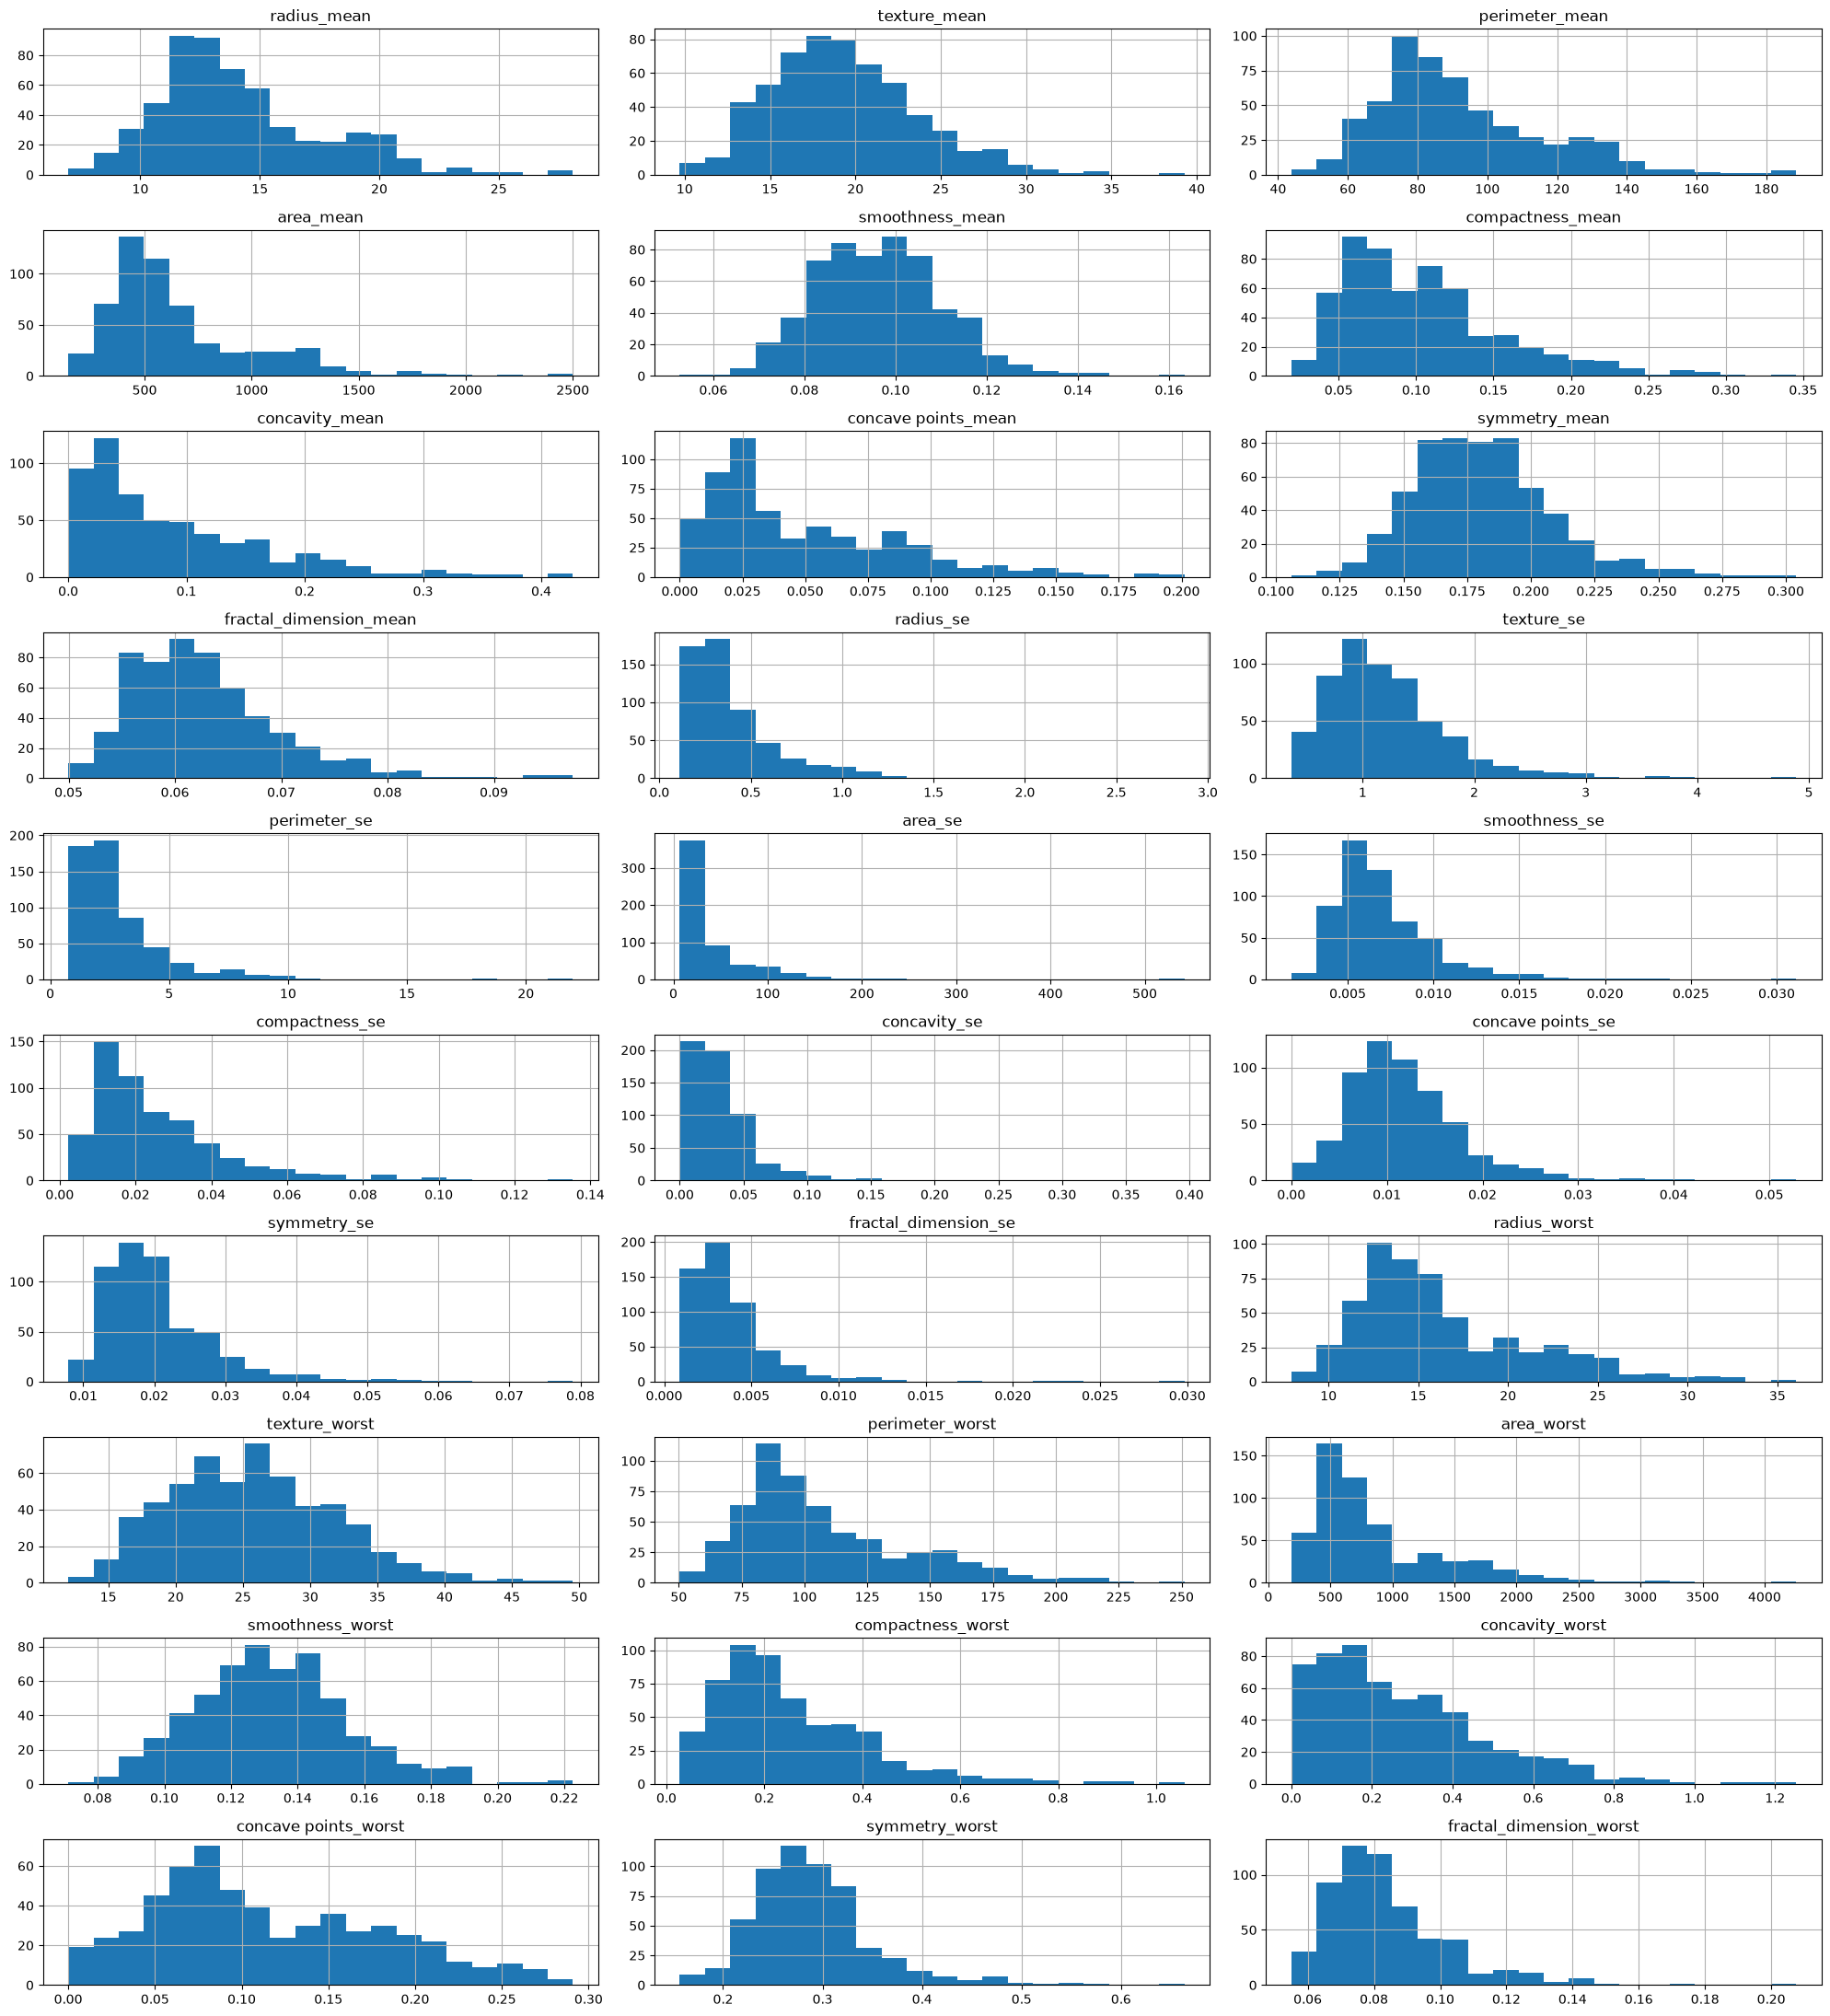

In [16]:
# Visualize the distribution of numerical features,
# These graphs help us understand how each feature is distributed
# and whether there are any possible outliers.د

df[numerical_features].hist(
    figsize=(20, 22),
    bins=20,
    layout=(10, 3)
)

plt.tight_layout()

#farhan shayanplt.show()

خب حالا وقت برسی هیستوگرام ها هست 
ما از اصطلاح اوت لایر ها استفاده می کنیم  که در واقع مقدار ندارند و کار رو یکم دشوار تر میکنه 

خب در اسپات پلیر مشاهده کردیم استاد کلسترول که صفربود رو با فیچر سن در کنار هم قرار داد و 
دیتا ها رو کنار هم قرار داد و متوجه ناترازی ها شد 

حالا در دیتاست ما  این موضوع درباره یک فیچر دیگه و ارتباط ان با فیچر دیگر 
صدق می کند یعنی شعاع توده  با تعداد نقاط فرورفته‌ی لبه‌ی توده

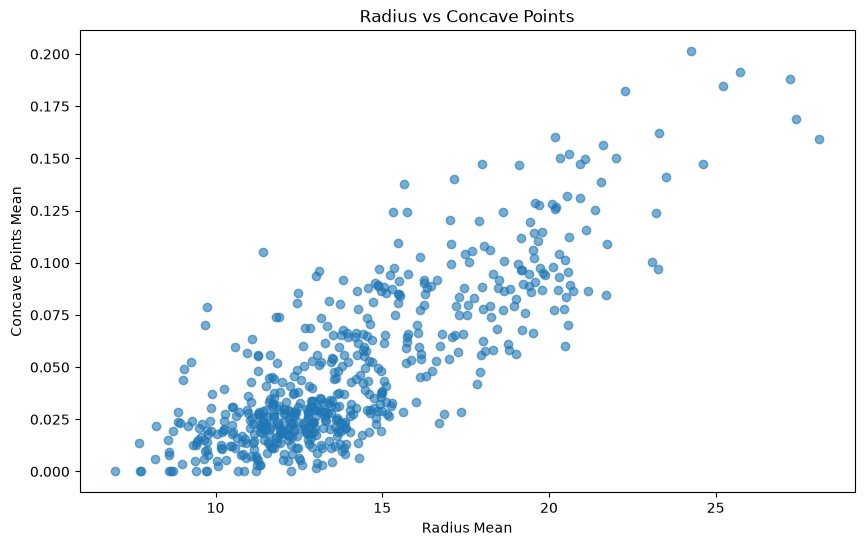

In [17]:
# Visualize the relationship between radius and concave points

plt.figure(figsize=(10, 6))

plt.scatter(
    df["radius_mean"],
    df["concave points_mean"],
    alpha=0.6
)

plt.title("Radius vs Concave Points")
plt.xlabel("Radius Mean")
plt.ylabel("Concave Points Mean")

plt.show()

plt.show()

برسی مقادیر مشکوک 

In [18]:
# Check records with zero concave points values

df[df["concave points_mean"] == 0]

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
101,862722,B,6.981,13.43,43.79,143.5,0.11700,0.07568,0.0,0.0,...,19.54,50.41,185.2,0.15840,0.12020,0.0,0.0,0.2932,0.09382,NaN
140,868999,B,9.738,11.97,61.24,288.5,0.09250,0.04102,0.0,0.0,...,14.10,66.53,342.9,0.12340,0.07204,0.0,0.0,0.3105,0.08151,NaN
174,871642,B,10.660,15.15,67.49,349.6,0.08792,0.04302,0.0,0.0,...,19.20,73.20,408.3,0.10760,0.06791,0.0,0.0,0.2710,0.06164,NaN
175,872113,B,8.671,14.45,54.42,227.2,0.09138,0.04276,0.0,0.0,...,17.04,58.36,259.2,0.11620,0.07057,0.0,0.0,0.2592,0.07848,NaN
192,875099,B,9.720,18.22,60.73,288.1,0.06950,0.02344,0.0,0.0,...,20.83,62.25,303.8,0.07117,0.02729,0.0,0.0,0.1909,0.06559,NaN
314,894047,B,8.597,18.60,54.09,221.2,0.10740,0.05847,0.0,0.0,...,22.44,56.65,240.1,0.13470,0.07767,0.0,0.0,0.3142,0.08116,NaN
391,903483,B,8.734,16.84,55.27,234.3,0.10390,0.07428,0.0,0.0,...,22.80,64.01,317.0,0.14600,0.13100,0.0,0.0,0.2445,0.08865,NaN
473,9113846,B,12.270,29.97,77.42,465.4,0.07699,0.03398,0.0,0.0,...,38.05,85.08,558.9,0.09422,0.05213,0.0,0.0,0.2409,0.06743,NaN
538,921092,B,7.729,25.49,47.98,178.8,0.08098,0.04878,0.0,0.0,...,30.92,57.17,248.0,0.12560,0.08340,0.0,0.0,0.3058,0.09938,NaN
550,923748,B,10.860,21.48,68.51,360.5,0.07431,0.04227,0.0,0.0,...,24.77,74.08,412.3,0.10010,0.07348,0.0,0.0,0.2458,0.06592,NaN


صفر بودن این مقدارها یعنی لبه‌ی توده کاملاً صاف هست و فرورفتگی بی    همه ی  این نمونه ها  خوش  خیم  ندارد. برخلاف کلسترول صفر که غیرممکن است، این حالت از نظر پزشکی ممکن و منطقی است. بنابراین این مقدارها خطای داده نیستند و آن‌ها را حذف یا اصلاح نمی‌کنی

حالا بریم ارتباط ویژگی های عددی را با یکدیگر چک کنیم 

In [19]:
# Calculate the correlation matrix for numerical features

correlation_matrix = df[numerical_features].assign(
    diagnosis_num=df["diagnosis"].map({"M": 1, "B": 0})
).corr()

correlation_matrix

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,diagnosis_num
radius_mean,1.000000,0.323782,0.997855,0.987357,0.170581,0.506124,0.676764,0.822529,0.147741,-0.311631,...,0.297008,0.965137,0.941082,0.119616,0.413463,0.526911,0.744214,0.163953,0.007066,0.730029
texture_mean,0.323782,1.000000,0.329533,0.321086,-0.023389,0.236702,0.302418,0.293464,0.071401,-0.076437,...,0.912045,0.358040,0.343546,0.077503,0.277830,0.301025,0.295316,0.105008,0.119205,0.415185
perimeter_mean,0.997855,0.329533,1.000000,0.986507,0.207278,0.556936,0.716136,0.850977,0.183027,-0.261477,...,0.303038,0.970387,0.941550,0.150549,0.455774,0.563879,0.771241,0.189115,0.051019,0.742636
area_mean,0.987357,0.321086,0.986507,1.000000,0.177028,0.498502,0.685983,0.823269,0.151293,-0.283110,...,0.287489,0.959120,0.959213,0.123523,0.390410,0.512606,0.722017,0.143570,0.003738,0.708984
smoothness_mean,0.170581,-0.023389,0.207278,0.177028,1.000000,0.659123,0.521984,0.553695,0.557775,0.584792,...,0.036072,0.238853,0.206718,0.805324,0.472468,0.434926,0.503053,0.394309,0.499316,0.358560
compactness_mean,0.506124,0.236702,0.556936,0.498502,0.659123,1.000000,0.883121,0.831135,0.602641,0.565369,...,0.248133,0.590210,0.509604,0.565541,0.865809,0.816275,0.815573,0.510223,0.687382,0.596534
concavity_mean,0.676764,0.302418,0.716136,0.685983,0.521984,0.883121,1.000000,0.921391,0.500667,0.336783,...,0.299879,0.729565,0.675987,0.448822,0.754968,0.884103,0.861323,0.409464,0.514930,0.696360
concave points_mean,0.822529,0.293464,0.850977,0.823269,0.553695,0.831135,0.921391,1.000000,0.462497,0.166917,...,0.292752,0.855923,0.809630,0.452753,0.667454,0.752399,0.910155,0.375744,0.368661,0.776614
symmetry_mean,0.147741,0.071401,0.183027,0.151293,0.557775,0.602641,0.500667,0.462497,1.000000,0.479921,...,0.090651,0.219169,0.177193,0.426675,0.473200,0.433721,0.430297,0.699826,0.438413,0.330499
fractal_dimension_mean,-0.311631,-0.076437,-0.261477,-0.283110,0.584792,0.565369,0.336783,0.166917,0.479921,1.000000,...,-0.051269,-0.205151,-0.231854,0.504942,0.458798,0.346234,0.175325,0.334019,0.767297,-0.012838


ویژگی  نقاط فرورفته‌ی بدترین حالت با بیشترین همبستگی مثبت را با بدخیم بودن دارد
محیط در بدترین حالت با مقدار هفتاد و هشت صدم 
شعاع در بدترین حالت هم با مقدار  هفتاد و هشت صدم از ویژگی‌های مهم است
نتیجه این است که هر چه توده بزرگ‌تر باشد و لبه‌ی ناصاف‌تری داشته باشد، احتمال بدخیم بودن آن بیشتر است 
ویژگی‌های  بعد فراکتالی میانگین بافت و خطای استاندارد و تقارن خطای استاندارد همبستگی نزدیک صفر
فرهان شایان

نقشه حرارتی همبستگی

نقشه حرارتی من با نقثشه حرارتی استاد  کاملا متفاوت است زیرا  دیتا ست و همچنین مقدار فیچر ها کاملا متفاوت است

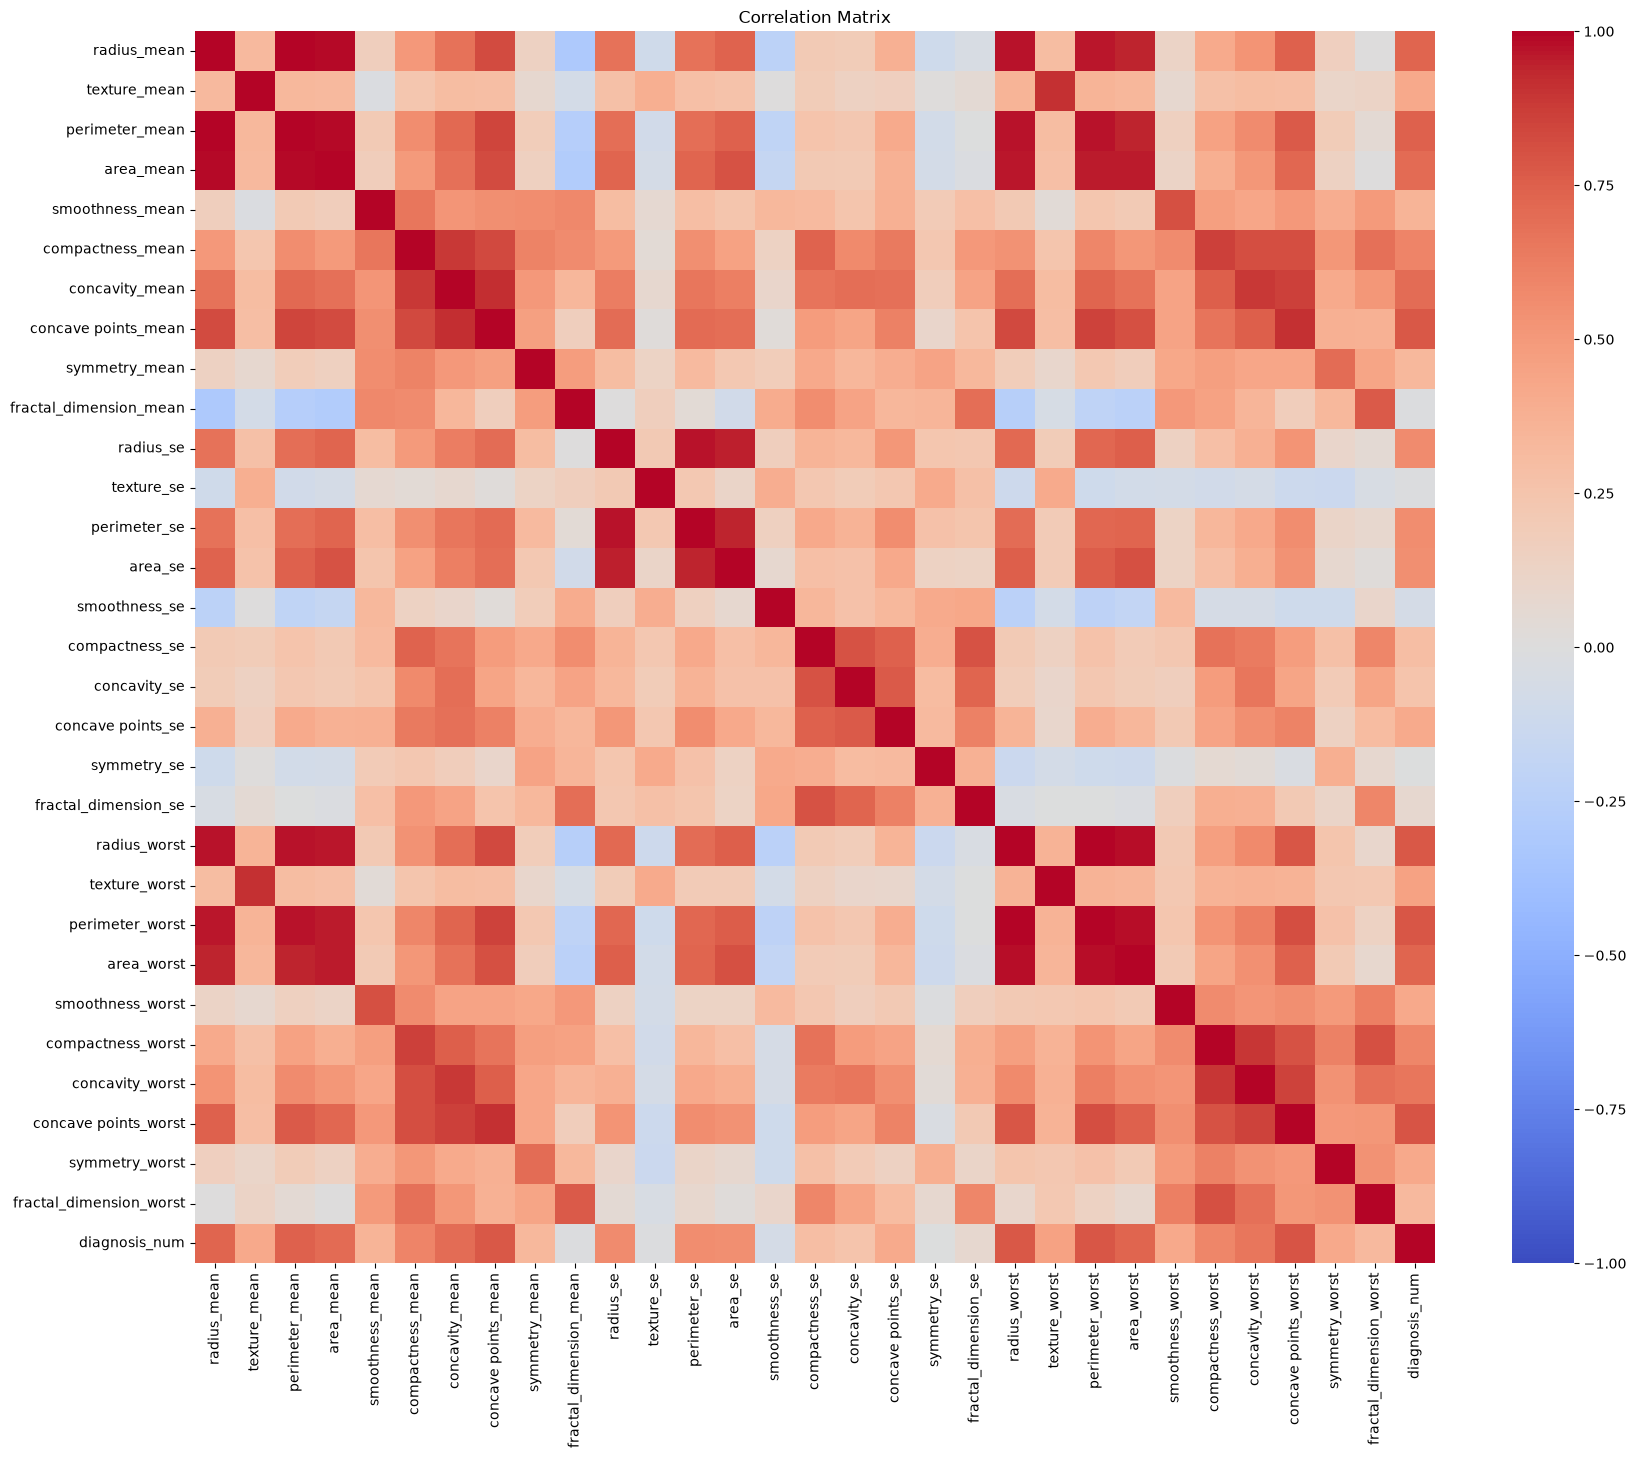

In [20]:
# Visualize correlations between numerical features and the target

plt.figure(figsize=(20, 16))

sns.heatmap(
    correlation_matrix,
    annot=False,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix")
plt.show()

درباره سامری در  ای  دی ای  ما تا انجا  مقادیر مختلف رو برسی کردیم 
برخی امار های توصیفی را برسی کردیم 
دیتا تایپ های دیتا ست رو گفتیم 
میسینگ ولیو ها رو برسی کردیم 
ستون های تکراری
هیستوگرام و نقشه حرارتی همبستگی
برسی مقادیرعدد 
بولین ها و کتگوریکال 
ماتریکس ها 

بریم سراغ یافته های کلیدی یا فایندینگ کی

دیتا ست شامل پانصد و شصت و نه ردیف و سی و سه ستون هست 
از ان ستون ها سی ستون ویژگی عددی هستند  و یک ستون  ستون تارگت هست نوع تومور را مشخص می کند
ردیف تکراری یافت نشد 
ستون شماره نمونه فقط برچسب است 
فقط یک ستون بی نام خالی است
تا اینجا ما سیصد و پنجاه و هفت نمونه خوش خیم و دویست و دوازده  نمونه بد خیم  داریم 
بین چند ویژگی مانند  شعاع و محیط و مساحت همبستگی بسیار بالا وجود دارد 
ویژگی های مانند  نقاط فرو رفته و اندازه توده بیشترین  ارتباط  را با بد خیم بودن نشان داده است 

فرهان شایان

در مرحله بعد 

ستون بی نام و ستون شماره نمونه را حذف می کنیم 

و داده های تارگت رو به باینری کلاسیفیکیشن  یا به عباری حروف را به اعداد تبدیل می کنیم

فرهان شایان